<a href="https://colab.research.google.com/github/yoonie03/data-science-toolkit/blob/library%2Fnumpy/Tutorial04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**[WIA1007 INTRODUCTION TO DATA SCIENCE]**
- WEEK4_TUTORIAL 04   
- Name : CHO YOONJEONG   
- OCC  : 1M   
- MATRIC NO. 26070633   


------------Tutorial 04-------------------

# Question 1: Identify the Problem

Consider this dataset:
```python
Student	Math	Science	English
Ali	75	80	72
Sara	88	91	85
John	65	70	68
```


1. Is this data in tidy format?
2. If not, explain which tidy-data rule is violated.
3. Using Python/pandas, reshape the dataset so that it has the columns:
   - Student
   - Subject
   - Score


In [14]:
import pandas as pd

data_Q1 = {
    "Student": ["Ali", "Sara", "John"],
    "Math": [75, 88, 65],
    "Science": [80, 91, 70],
    "English": [72, 85, 68]
}

df1 = pd.DataFrame(data_Q1)
df1

,Student,Math,Science,English
0,Ali,75,80,72
1,Sara,88,91,85
2,John,65,70,68


**1. Is this data in tidy format?**
- No, the dataset is not in tidy format.

**2. If not, explain which tidy-data rule is violated.**
- It violates Rule #1: Variables are in columns. The subject variable is spread across three columns (Math, Science, and English) instead of being stored in one column.

**3. Using Python/pandas, reshape the dataset so that it has the columns:**
   - Student
   - Subject
   - Score

In [15]:

students = []
subjects = []
scores = []

for i in range(3):
    for subject in ["Math", "Science", "English"]:
        students.append(df1["Student"][i])
        subjects.append(subject)
        scores.append(df1[subject][i])

tidy_df1 = pd.DataFrame({
    "Student": students,
    "Subject": subjects,
    "Score": scores
})

tidy_df1


,Student,Subject,Score
0,Ali,Math,75
1,Ali,Science,80
2,Ali,English,72
3,Sara,Math,88
4,Sara,Science,91
5,Sara,English,85
6,John,Math,65
7,John,Science,70
8,John,English,68



# Question 2: Sales Data

You are given:
```python
Country   Q1_Sales   Q2_Sales   Q3_Sales   Q4_Sales
Malaysia    12000      15000      14000      18000
Thailand    10000      11000      13000      16000
Indonesia   14000      12500      15000      17000
```

In [16]:
import pandas as pd

data_Q2 = {
    "Country": ["Malaysia", "Thailand", "Indonesia"],
    "Q1_Sales": [12000, 10000, 14000],
    "Q2_Sales": [15000, 11000, 12500],
    "Q3_Sales": [14000, 13000, 15000],
    "Q4_Sales": [18000, 16000, 17000]
}

df_Q2 = pd.DataFrame(data_Q2)
df_Q2

,Country,Q1_Sales,Q2_Sales,Q3_Sales,Q4_Sales
0,Malaysia,12000,15000,14000,18000
1,Thailand,10000,11000,13000,16000
2,Indonesia,14000,12500,15000,17000


**1. What is the tidy-data problem with this dataset?**

- The dataset violates **Rule #1: Variables are in columns**. The quarter variable is spread across four columns (Q1_Sales, Q2_Sales, Q3_Sales, and Q4_Sales) instead of being stored in one column.


**2. Use pandas to convert it into:**
```python
Country    Quarter    Sales
Malaysia   Q1         12000
Malaysia   Q2         15000
```

> **About `pd.melt()`**

I found the `pd.melt()` function in the Pandas documentation. It is used to reshape a DataFrame from **wide format to long format** by converting multiple columns into rows.

- `id_vars`: Columns to keep unchanged.
- `var_name`: Name of the new variable column.
- `value_name`: Name of the new value column.

**Reference:** [Pandas Official Documentation – pandas.melt](https://pandas.pydata.org/docs/reference/api/pandas.melt.html)

In [17]:
tidy_Q2 = pd.melt(
    df_Q2,
    id_vars=["Country"],
    var_name="Quarter",
    value_name="Sales"
)

tidy_Q2["Quarter"] = tidy_Q2["Quarter"].str.replace("_Sales", "")

tidy_Q2

,Country,Quarter,Sales
0,Malaysia,Q1,12000
1,Thailand,Q1,10000
2,Indonesia,Q1,14000
3,Malaysia,Q2,15000
4,Thailand,Q2,11000
5,Indonesia,Q2,12500
6,Malaysia,Q3,14000
7,Thailand,Q3,13000
8,Indonesia,Q3,15000
9,Malaysia,Q4,18000


# Question 3: Asking Questions from Data
Consider this dataset
```python
data = {"Student": ["A", "B", "C", "D", "E", "F"],
        "Study_Hours": [2, 5, 3, 7, 4, 8],
        "Score": [55, 72, 60, 85, 68, 90]}
```

In [18]:
data = {"Student": ["A", "B", "C", "D", "E", "F"],
        "Study_Hours": [2, 5, 3, 7, 4, 8],
        "Score": [55, 72, 60, 85, 68, 90]}

df_Q3 = pd.DataFrame(data)
df_Q3

,Student,Study_Hours,Score
0,A,2,55
1,B,5,72
2,C,3,60
3,D,7,85
4,E,4,68
5,F,8,90


Using Python:
1. What is the average study time?

In [19]:
print(df_Q3["Study_Hours"].mean())


4.833333333333333


2. What is the average score?

In [20]:
print(df_Q3["Score"].mean())

71.66666666666667


3. Which student obtained the highest score?

In [21]:
print(df_Q3.loc[df_Q3["Score"].idxmax(), "Student"])

F


4. Which student studied the most?

In [22]:
print(df_Q3.loc[df_Q3["Study_Hours"].idxmax(), "Student"])

F


**5. Question: Does studying more hours appear to be associated with a higher score?**
- Yes, students who studied more hours generally received higher scores. For example, Student A studied for 2 hours and scored 55, while Student F studied for 8 hours and scored 90. Therefore, there appears to be a positive relationship between study hours and scores.

**6. Create a scatter plot of Study_Hours vs Score.**

<Axes: title={'center': 'Study Hours vs Score'}, xlabel='Study_Hours', ylabel='Score'>

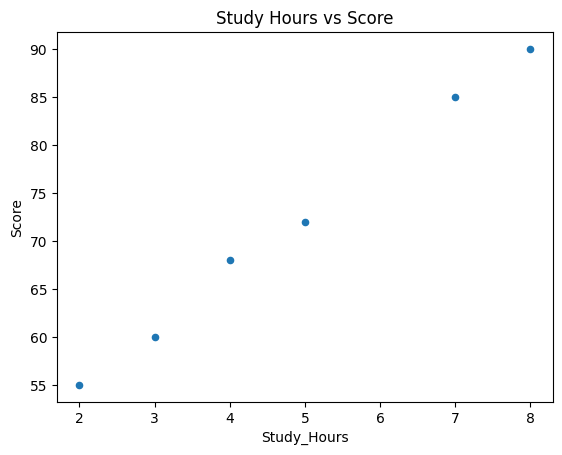

In [23]:
df_Q3.plot.scatter(
    x="Study_Hours",
    y="Score",
    title="Study Hours vs Score"
)